# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі запускаємо локально через [Ollama](https://ollama.com) і звертаємося до нього звичайними HTTP-запитами.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.15


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.1 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.8 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.9 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.6 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.22,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.78,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.84,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.91,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

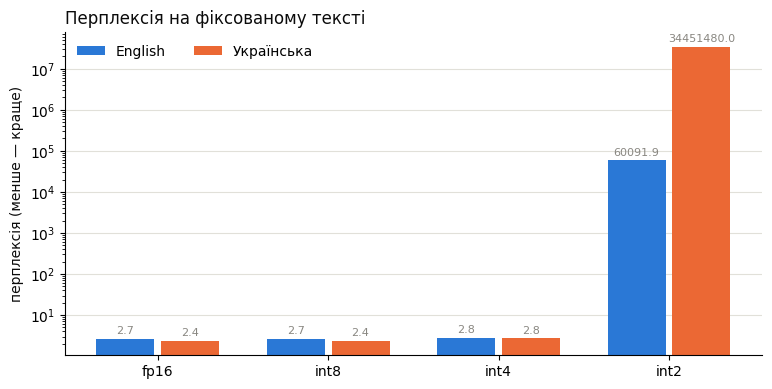

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "A", 3: "=", 4: "B", 5: "="}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 2, int4 краща: 1, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

# Відповіді на теоретичні питання (розділ 0.1)

Нижче відповіді на питання 1–20. Де потрібен код, він наведений у клітинках перед відповіддю; усі клітинки виконані, результати видно у виводі.

In [ ]:
# Питання 1: як токенізатор «бачить» слово
word = "трансформер"
ids = tokenizer(word, add_special_tokens=False).input_ids
print("токени:", [tokenizer.decode([i]) for i in ids], "→", len(ids), "токени")
print("справжня кількість літер «р»:", word.count("р"))
spelled = " ".join(word)
ids2 = tokenizer(spelled, add_special_tokens=False).input_ids
print("слово по літерах:", [tokenizer.decode([i]) for i in ids2])
r = chat(INSTRUCT_MODEL, f"Скільки разів літера «р» трапляється тут: {spelled}? Відповідай одним числом.")
print("модель, слово по літерах:", r["message"]["content"])


токени: ['т', 'ран', 'с', 'форм', 'ер'] → 5 токени
справжня кількість літер «р»: 3
слово по літерах: ['т', ' р', ' а', ' н', ' с', ' ф', ' о', ' р', ' м', ' е', ' р']
модель, слово по літерах: Трійка літер «р» у слові **трансформер**.

Підсумок: **3**.

Відповідь: **3**


### 1. Підрахунок літер «р» у слові «трансформер»

**Відповідь.** Модель працює не з літерами, а з *токенами* — шматками слів. Токенізатор розбиває «трансформер» на п’ять токенів: `'т', 'ран', 'с', 'форм', 'ер'`. Літера «р» ховається всередині токенів «ран», «форм», «ер», і на вході модель її окремо не бачить: їй потрібно «прогадати» орфографію кожного токена з пам’яті навчання. Мала модель (1.7B) робить це ненадійно. Без міркувань вона просто вгадує («1 раз», розбивши слово на «транс» і «формер»). У режимі міркування вона спершу «розписує» слово по літерах, але вже цей крок робить з помилкою (т-р-а-н-с-т-о-м-е-р: загубила «ф», додала «м»), і помилка просто переходить у відповідь (2 замість 3). Міркування допомагає розбити задачу на кроки, але не дає моделі нових знань про правопис слова.

**Підтвердження кодом.** Токенізатор дійсно ділить слово на 5 шматків, а Python рахує правильно (3 літери). Якщо ж подати слово через пробіли, кожна літера стає окремим токеном, і модель відповідає правильно («Трійка літер «р»…») — проблема саме в токенізації, а не в тому, що модель не розуміє задачу.

In [ ]:
# Питання 5 і 6: пофразові метрики для fp16 та зменшення памʼяті
print("--- Питання 5: переклади fp16, метрики по кожному реченню ---")
for i, (src, ref) in enumerate(TRANSLATION):
    hyp = records["fp16"]["переклади"][i]
    c = chrf.compute(predictions=[hyp], references=[[ref]])["score"]
    b = bleu.compute(predictions=[hyp], references=[[ref]])["score"]
    print(f"{i}: chrF={c:5.1f} BLEU={b:5.1f} | модель: {hyp} | еталон: {ref}")

print()
print("--- Питання 6: у скільки разів зменшилась памʼять і швидкість ---")
mem = summary["памʼять моделі, GB"]
print("зменшення памʼяті (fp16 / варіант):", (mem["fp16"] / mem).round(2).to_dict())
print("tokens/s:", summary["tokens/s"].to_dict())


--- Питання 5: переклади fp16, метрики по кожному реченню ---
0: chrF= 49.9 BLEU= 10.0 | модель: Зустріч була перенесена на четвер, о 15 годин. | еталон: Зустріч перенесли на четвер на третю годину.
1: chrF= 73.1 BLEU= 52.7 | модель: Надішліть мені звіт до кінця дня. | еталон: Будь ласка, надішліть мені звіт до кінця дня.
2: chrF= 36.7 BLEU=  6.4 | модель: Бібліотека закривається у неділі та дні відпочинку. | еталон: Бібліотека не працює в неділю та у святкові дні.
3: chrF= 60.7 BLEU= 24.8 | модель: Наша команда виправила баг, але тестування все ще не працюють. | еталон: Наша команда виправила помилку, але тести все ще не проходять.
4: chrF= 37.1 BLEU= 13.1 | модель: Завтра піде дощ, тому взміть засіб. | еталон: Завтра буде дощ, тож візьміть парасольку.
5: chrF= 52.4 BLEU= 16.5 | модель: Новий модель менший, але відповідає почти так само, як і старий. | еталон: Нова модель менша, але відповідає майже так само добре, як стара.
6: chrF= 41.7 BLEU=  8.5 | модель: Я бажаю забронювати стіл 

### 2. Як змінюються перплексія й метрики перекладу від fp16 до int2

| варіант | перплексія, English | перплексія, Українська | chrF | BLEU |
|---|---|---|---|---|
| fp16 | 2.67 | 2.40 | 55.22 | 23.71 |
| int8 | 2.67 | 2.40 | 58.25 | 26.17 |
| int4 | 2.81 | 2.76 | 55.34 | 29.79 |
| int2 | 60 091.86 | 34 451 480 | 0.19 | 0.12 |

Від fp16 до int8 перплексія не змінюється зовсім. В int4 вона трохи зростає (English на 5%, українська на 15%), а метрики перекладу лишаються на рівні fp16 (chrF 55.2 проти 55.3; те, що BLEU навіть вищий, — шум: у нас лише 10 коротких речень і один еталон на кожне). В int2 модель ламається: перплексія зростає в десятки тисяч і мільйони разів, chrF і BLEU падають майже до нуля. **Найбільший стрибок — між int4 та int2**: перплексія English зростає приблизно в 21 000 разів (2.81 → 60 092), українська — приблизно в 12 мільйонів разів (2.76 → 34 451 480), chrF падає з 55.3 до 0.2.

### 3. Чи однаково зростає перплексія для англійської й української

Ні. В int4 перплексія English зростає в 1.05 раза (2.67 → 2.81), а української — в 1.15 раза (2.40 → 2.76), тобто українська втрачає втричі більше у відносних числах. В int2 українська ламається ще сильніше (3.4 · 10^7 проти 6 · 10^4). Абсолютні значення порівнювати між мовами не можна (див. питання 13), але порівнювати відносне зростання відносно власного fp16 можна. Результат узгоджується з висновком слайда «Де може просідати якість при квантизації»: першими втрачають якість мови й задачі, які менше представлені в навчальних даних, а англійська, яка домінує в даних, тримається довше.

### 4. Сліпе порівняння (розділ 2.5) і автоматичні метрики

У сліпому порівнянні fp16 була кращою у 2 запитах із 5 (запити 2 і 4), int4 — в 1 (запит 1), ще у 2 (запити 3 і 5) відповіді були однаково якісні. Автоматичні метрики майже не побачили різниці між fp16 та int4 (chrF 55.22 проти 55.34, перплексія +5% і +15%), а очима різницю помітно саме у вільній генерації українською: int4 частіше будує дивні звороти («з акцентом на засвоєння основних інших навичок», «з меншою відповідністю до об'ємних ресурсів»), а от у запиті 1 коротший лист int4 мені навіть сподобався більше. На англійському поясненні та коді (запити 3 і 5) різниці майже немає. Тобто метрики на 10 коротких реченнях не помітили дрібних втрат, які видно в довших текстах українською, — і це співпадає з тим, що перплексія на українській зросла сильніше.

### 5. Правильний переклад, що відрізняється від еталона словами

Речення з індексом 8 (код вище, клітинка до питань 5–6): модель fp16 переклала «Студенти повинні подати свою лабораторну роботу до терміну.», еталон — «Студенти мають здати лабораторну роботу до кінцевого терміну.». Зміст той самий (повинні/мають, подати/здати — синоніми), але chrF = 60.5, BLEU = 23.4. Подібно: «перевірте журнал» замість «перевірте логи» (індекс 9) дає chrF 83.7, BLEU 60.8, а «закривається у неділі та дні відпочинку» замість «не працює в неділю та у святкові дні» (індекс 2) — лише chrF 36.7 і BLEU 6.4. BLEU рахує збіг слів (послідовності слів), тож синонім для нього така сама помилка, як і хибне слово, і оцінка різко падає. chrF збіги символів, тому до синонімів і змін закінчень поблажливіший, але теж оцінює схожість написання, а не зміст. Для порівняння: невірний переклад «Завтра піде дощ, тому взміть засіб» (парасолька → «засіб», індекс 4) має chrF 37.1 і BLEU 13.1 — не менше, ніж правильний переклад про бібліотеку. Висновок: метрики з одним еталоном не відрізняють правильний переклад в інших словах від хибного.

### 6. У скільки разів зменшилась памʼять і чи стала генерація швидшою

Памʼять моделі: fp16 8.04 GB → int8 4.42 GB (у 1.82 раза), int4 2.73 GB (у 2.95 раза), int2 1.81 GB (у 4.44 раза). Не рівно у 2, 4 і 8 разів, бо: (1) квантизуються лише ваги лінійних шарів (близько 3.63 з 4.02 млрд параметрів), а ембединги (0.39 млрд параметрів = 0.78 GB у fp16) і нормалізації лишаються у 16 бітах; (2) в int4 та int2 до кожного блоку ваг додаються масштаби (приблизно 0.12–0.14 GB). Розрахунок у клітинці до питань 11, 12 і 14 збігається з таблицею: int8 — 4.41 GB, int4 — 2.59 + масштаби, int2 — 1.69 + масштаби. Генерація швидшою не стала, навпаки: 17.2 tokens/s (fp16) → 5.8 (int8) → 2.8 (int4) → 2.9 (int2). T4 не вміє множити числа в int8/int4/int2 напряму, тому перед кожним множенням ваги розпаковуються в fp16 (у нашому коді — ще й на чистому PyTorch, без швидких CUDA-ядер), і ці накладні витрати з надлишком перекривають виграш від меншого обсягу даних.

In [ ]:
# Питання 7: як змусити Base-модель відповісти, а не продовжити текст
def raw(prompt, n=30):
    r = ollama("/api/generate", {"model": BASE_MODEL, "prompt": prompt, "raw": True, "stream": False,
                                 "options": {"temperature": 0, "seed": 1, "num_predict": n, "stop": ["\n"]}})
    return r["response"]

print("Просто питання:       ", repr(raw(QUESTION)))
print("Питання + 'Відповідь:'", repr(raw(QUESTION + "\nВідповідь:")))
print("Формат Q/A:           ", repr(raw("Питання: " + QUESTION + "\nВідповідь:")))

Просто питання:        ' Як називається найбільша річка Франції? Як називається найбі'
Питання + 'Відповідь:' ' Париж'
Формат Q/A:            ' Париж'


In [ ]:
# Питання 9: задача, де без міркування модель помиляється, а з міркуванням — ні
q = "Аня, Борис і Віка мають різні професії: лікар, інженер, вчитель. Аня не лікар. Борис не вчитель і не лікар. Хто з них вчитель?"
print("Промпт:", q)
for think in (False, True):
    r = chat(INSTRUCT_MODEL, q, think=think)
    print(f"\n=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
    print(r["message"]["content"])


Промпт: Аня, Борис і Віка мають різні професії: лікар, інженер, вчитель. Аня не лікар. Борис не вчитель і не лікар. Хто з них вчитель?

=== think=False | токенів: 369 | генерація: 3.5 с
Давайте розглянемо умови задачі:

**Підписники:**
- Аня
- Борис
- Віка

**Професії:**
- Лікар
- Інженер
- Вчитель

**Умови:**
1. Аня не лікар.
2. Борис не вчитель і не лікар.
3. Підбір професії для кожного з трьох людей.

---

### Крок 1: Визначення професії Бориса

Борис не вчитель і не лікар. Залишається **інженер**.

**Висновок:**
- Борис — інженер.

---

### Крок 2: Визначення професії Ани

Аня не лікар. Залишається **вчитель** і **інженер**.

Однак **інженер** вже відповідно Борис, тому Аня — **вчитель**.

**Висновок:**
- Аня — вчитель.

---

### Крок 3: Визначення професії Віки

Останній професія — **інженер** (вже відповідно Борис), **лікар** (відповідно Аня), тому **Віка — вчитель**.

---

### Відповідь:

**Віка — вчитель.**

=== think=True | токенів: 836 | генерація: 8.4 с
**Розв'язання:**

1. 

### 7. Чому Base-модель відповідає новими питаннями

Base-модель навчена лише передбачати наступний токен в текстах з інтернету; вона не знає, що від неї чекають відповіді (її не донавчали на парах «інструкція → відповідь» і не давали їй chat template). Рядок «Яка столиця Франції?» в інтернеті часто стоїть у списку вікторини, тесту або на форумі, де за ним йдуть ще питання, тому найімовірніше продовження — ще питання. Щоб модель відповіла, треба подати їй не питання, а початок документа, де відповідь — натуральне продовження. В клітинці вище (промпт з словом «Відповідь:» і зупинкою на першому рядку): без цього модель дає «Як називається найбільша річка Франції? …», з промптом «Яка столиця Франції?\nВідповідь:» — «Париж», і з форматом «Питання: …\nВідповідь:» — теж «Париж».

### 8. Скільки токенів і часу забрали міркування; чому англійською

Без міркувань: 252 токени і 2.1 с; з міркуванням: 569 токенів і 4.8 с. Тобто в 2.3 раза більше токенів і часу (понад 300 додаткових токенів: лише це міркування було 1410 символів тексту) — і весь цей час користувач не бачить відповіді, тож TTFT зростає. Міркує модель англійською, імовірно, тому що ланцюжки міркувань, на яких її донавчали (знову ж «за замовчуванням» навчання на міркування йде переважно англійською та китайською), були переважно англомовними; англійська — «робоча мова» моделі, де вона найбільше бачила прикладів розвʼязання задач. А фінальну відповідь вона дає мовою питання, бо цей звичай (відповідати мовою користувача) закладено в Instruct-навчанні.

### 9. Задача, яку модель вирішує тільки з міркуванням

**Промпт:** «Аня, Борис і Віка мають різні професії: лікар, інженер, вчитель. Аня не лікар. Борис не вчитель і не лікар. Хто з них вчитель?» Правильна відповідь: Борис — інженер (він не лікар і не вчитель), отже Аня, яка не лікар, — вчителька, а Віка — лікар.

- **Без міркування** (369 токенів): «Віка — вчитель» — **неправильно**. Відповідь ще й суперечить сама собі: спочатку вона називає вчителем Аню, а в кінці знову вчителем, але вже Віку.
- **З міркуванням** (836 токенів): «Аня є вчителем» — **правильно** (модель спершу визначила, що Борис — інженер, потім що Аня не лікар).

Повні відповіді — у виводі клітинки вище.

### 10. Навіщо temperature: 0 і seed: 1

При temperature = 0 модель обирає завжди найімовірніший токен (greedy-декодування), а seed фіксує генератор випадкових чисел на випадок, якщо сервер все ж щось семплує. Разом це дає відтворюваність: один і той самий запит дає одну й ту саму відповідь. Це потрібно, щоб різниця між режимами (think=True/False) або між Base і Instruct була наслідком самих моделей, а не випадкового семплінгу, і щоб результати ноутбука повторювалися при перезапуску.

In [ ]:
# Питання 13: перплексія fp16-моделі на осмисленому тексті та на випадкових словах
import random

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)
rnd = random.Random(0)

def shuffled(text):
    words = text.replace(",", "").replace(".", "").replace(":", "").replace("—", "").split()
    rnd.shuffle(words)
    return " ".join(words)

for lang, text in PPL_TEXT.items():
    mixed = shuffled(text)
    print(f"{lang}: осмислений текст {perplexity(model, text):8.1f} | ті самі слова у випадковому порядку {perplexity(model, mixed):8.1f} | токенів у тексті: {len(tokenizer(text).input_ids)}")

# крайній випадок: 60 випадкових токенів зі словника
g = torch.Generator().manual_seed(0)
ids = torch.randint(0, 150000, (1, 60), generator=g).to(DEVICE)
with torch.no_grad():
    loss = model(ids, labels=ids).loss
print(f"60 випадкових токенів: {float(torch.exp(loss)):.0f} (розмір словника: {tokenizer.vocab_size + len(tokenizer.get_added_vocab())})")

del model
gc.collect()
torch.cuda.empty_cache()


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

English: осмислений текст      2.7 | ті самі слова у випадковому порядку    395.0 | токенів у тексті: 126
Українська: осмислений текст      2.4 | ті самі слова у випадковому порядку     15.0 | токенів у тексті: 348
60 випадкових токенів: 1565866 (розмір словника: 151669)


In [ ]:
# Питання 11, 12 і 14: bf16 на T4, кількість параметрів, памʼять моделі та KV-кеш
from accelerate import init_empty_weights
from transformers import AutoConfig

print("--- Питання 11 ---")
print("GPU:", torch.cuda.get_device_name(), "| compute capability:", torch.cuda.get_device_capability())
try:
    print("bf16 апаратно підтримується:", torch.cuda.is_bf16_supported(including_emulation=False))
except TypeError:
    print("bf16 підтримується (з емуляцією):", torch.cuda.is_bf16_supported())

print("--- Питання 12 ---")
cfg = AutoConfig.from_pretrained(MODEL_ID)
with init_empty_weights():
    empty = AutoModelForCausalLM.from_config(cfg)
empty.tie_weights()  # вихідний шар ділить ваги з ембедингами, рахуємо їх один раз
params = sum(p.numel() for p in empty.parameters())
emb = cfg.vocab_size * cfg.hidden_size
print(f"параметрів: {params / 1e9:.2f} млрд")
print(f"памʼять fp16 за формулою (параметри x 2 байти): {params * 2 / 1e9:.2f} GB; у таблиці 2.4: {summary.loc['fp16', 'памʼять моделі, GB']} GB")

print("--- Питання 6 і 14: звідки береться різниця ---")
print(f"ембединги (не квантизуються): {emb / 1e9:.2f} млрд параметрів = {emb * 2 / 1e9:.2f} GB у fp16")
linear = params - emb
for name, bits in [("int8", 8), ("int4", 4), ("int2", 2)]:
    est = (linear * bits / 8 + emb * 2) / 1e9
    print(f"{name}: оцінка без масштабів {est:.2f} GB; у таблиці {summary.loc[name, 'памʼять моделі, GB']} GB")
kv_per_token = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * cfg.head_dim * 2
print(f"KV-кеш: {kv_per_token / 1e3:.0f} KB на токен, {kv_per_token * 4096 / 1e9:.2f} GB на 4096 токенів контексту")
print("пік VRAM - памʼять моделі, GB:", (summary["пік VRAM, GB"] - summary["памʼять моделі, GB"]).round(2).to_dict())
del empty


--- Питання 11 ---
GPU: Tesla T4 | compute capability: (7, 5)
bf16 апаратно підтримується: False
--- Питання 12 ---
параметрів: 4.02 млрд
памʼять fp16 за формулою (параметри x 2 байти): 8.04 GB; у таблиці 2.4: 8.04 GB
--- Питання 6 і 14: звідки береться різниця ---
ембединги (не квантизуються): 0.39 млрд параметрів = 0.78 GB у fp16
int8: оцінка без масштабів 4.41 GB; у таблиці 4.42 GB
int4: оцінка без масштабів 2.59 GB; у таблиці 2.73 GB
int2: оцінка без масштабів 1.69 GB; у таблиці 1.81 GB
KV-кеш: 147 KB на токен, 0.60 GB на 4096 токенів контексту
пік VRAM - памʼять моделі, GB: {'fp16': 0.6, 'int8': 0.59, 'int4': 0.59, 'int2': 0.58}


### 11. Чому fp16, а не bf16, і що показує get_device_capability()

На T4 torch.cuda.get_device_capability() повертає (7, 5) — це архітектура Turing. Апаратна підтримка bf16 починається з compute capability 8.0 (Ampere: A100, RTX 30xx і новіші), і torch.cuda.is_bf16_supported(including_emulation=False) на T4 повертає False. Тому bf16 тут або не працює, або емулюється великими втратами швидкості. fp16 тензорні ядра T4 підтримують. Для інференсу готової моделі діапазону fp16 (до 65504) зазвичай вистачає, тому різниця з bf16 практично непомітна.

### 12. Кількість параметрів і памʼять fp16

У Qwen3-4B-Instruct-2507 4.02 млрд параметрів (рахуємо їх з конфігурації моделі без завантаження ваг; ваги ембедингів і вихідного шару спільні і рахуються один раз). За формулою «параметри × байти на параметр»: 4.02 × 10^9 × 2 байти (fp16) = 8.04 GB. У таблиці розділу 2.4 «памʼять моделі» для fp16 — 8.04 GB, тобто збігається до сотих.

### 13. Що таке перплексія і чому її не можна порівнювати між мовами

Перплексія — це exp(середня похибка передбачення наступного токена), тобто «в середньому між скількома однаково імовірними токенами модель вагається»: 1 — ідеальне передбачення, чим більше — тим гірше. Рахується на кожен токен, а не на слово чи символ, і токенізатор ділить різні мови по-різному: текст про фотосинтез англійською — 126 токенів, українською — 348. У українському тексті багато «легких» токенів (друга чи третя частина слова, яку можна вгадати), тому середня величина на токен залежить не лише від якості моделі, але й від того, як нарізано текст; тексти й теми теж різні. Тому порівнювати слід лише різні моделі/квантизації на тому самому тексті однієї мови.

Експеримент (клітинка вище, fp16): осмислений текст — 2.7 (English) і 2.4 (українська); ті самі слова у випадковому порядку — 395.0 (English) і 15.0 (українська); 60 випадкових токенів зі словника — приблизно 1.6 млн, ще більше за розмір словника (151 669). **Пояснення:** без звʼязності контекст нічого не підказує, тому модель на кожному слові вагається між сотнями варіантів. Перплексія випадкових токенів навіть більша за розмір словника: модель твердо «очікує» звичайний текст, і коли приходить випадкова послідовність, випадковий токен має ще меншу ймовірність, ніж при рівномірному виборі. Українська «каша» (15 проти 395) виглядає приємніше, бо більша частина її токенів — продовження вже початого слова, яке легко вгадати без контексту; це ще одне підтвердження, що числа між мовами не порівняні.

### 14. Чому «пік VRAM» більший за «памʼять моделі»

Різниця в усіх варіантах однакова, близько 0.6 GB (0.60 / 0.59 / 0.59 / 0.58). Під час генерації памʼять займають не лише ваги: **KV-кеш** (ключі й значення уваги всіх попередніх токенів: для цієї моделі 147 KB на токен, тобто 0.60 GB на контекст у 4096 токенів; у наших коротких запитах він малий), **активації** проміжних шарів, **логіти** (тензор «довжина послідовності × 151 669» на виході), тимчасові буфери (у int8/int4/int2 — розпаковані у fp16 ваги поточного шару; під час завантаження — шар до квантизації) та робочі буфери PyTorch. Квантизація стискає лише ваги, тому ця надбавка майже не залежить від варіанта, а на довгих контекстах KV-кеш буде рости й стане вагомішою частиною піку.

### 15. Скільки разів обрано fp16, int4 чи «однаково»

З 5 порівнянь: fp16 — 2 рази, int4 — 1 раз, «однаково» — 2 рази (див. підсумок клітинки після VOTES). Під час цього висновки робити надійно не можна: зміна одного голосу міняє картину повністю. Навіть рахуючи простий знаковий критерій (без «нічиї»), 5 з 5 на користь одного варіанта дає p = 2 · (1/2)^5 ≈ 0.06, тобто ще не значуще на рівні 5%. Для надійного висновку треба значно більше: щоб оцінити частку перемог з похибкою ±10% потрібно приблизно 100 порівнянь (n ≈ 1.96² · 0.25 / 0.1² ≈ 96), для ±5% — близько 400; а щоб помітити невелику перевагу 60 : 40 на рівні значущості 5% і потужності 80% — приблизно 200. При цьому запити мають бути різноманітними, а оцінювачів — кілька.

### 16. Як «ламається» модель у int2 і чи видно це вже в int4

У int2 (розділ 2.6 і таблиця перекладів) відповіді перестають бути мовою: вихід — набір випадкових уривків слів, символів та китайських ієрогліфів між якими повторюються одні й ті самі токени («taken», «ever», «again», «hhhh»), нулі, зворотні косі риски та «�». Відповідь не має жодного звʼязку з питанням, мова не вибирається (на українське питання — англійські слова й сміття), модель зациклюється на одному символі до кінця ліміту; на коді — не вийшло ні одного рядка Python. Перплексія тут досягає десятків тисяч і мільйонів, тобто модель гірша за випадкове вгадування. Це зрозуміло: на кожну вагу у лінійних шарах лишається тільки 4 можливі значення, похибки накопичуються від шару до шару (в моделі 36 шарів), і на виході залишається шум.

У int4 до цього далеко: мова граматична й по темі, але **перші ознаки вже є**: дрібні лексичні помилки та дивні фрази («з акцентом на засвоєння основних інших навичок», «Навчіть себе»), вигаданий зміст у перекладах («Бібліотека відкрита тільки з 1 по 7» замість «не працює в неділю та у святкові дні»; «Зареєструвати стіл» замість «забронювати»), коротші й менш повні відповіді, перплексія українською +15%. У fp16 теж є помилки («взміть засіб»), але в int4 їх більше, і вони зачіпають зміст, а не лише форму.

In [ ]:
# Питання 17: та сама секція 2 для меншої моделі Qwen/Qwen3-1.7B (перплексія і переклад)
MODEL_SMALL = "Qwen/Qwen3-1.7B"
tok_small = AutoTokenizer.from_pretrained(MODEL_SMALL)

def ppl_small(model, text):
    ids = tok_small(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))

def translate_small(model, src):
    # у Qwen3-1.7B увімкнений режим міркування, тому вимикаємо його, щоб порівнювати з 4B-Instruct
    text = tok_small.apply_chat_template([{"role": "user", "content": TRANSLATE_PROMPT.format(src)}],
                                         tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tok_small(text, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=80, do_sample=False)
    return tok_small.decode(out[0, inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()

small = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    model = AutoModelForCausalLM.from_pretrained(MODEL_SMALL, dtype=DTYPE, device_map=DEVICE, quantization_config=config)
    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = ppl_small(model, text)
    hyps = [translate_small(model, src) for src, _ in TRANSLATION]
    r["chrF"] = chrf.compute(predictions=hyps, references=references)["score"]
    r["BLEU"] = bleu.compute(predictions=hyps, references=references)["score"]
    small[name] = r
    print(f"{name}: готово")
    del model

small_df = pd.DataFrame(small).T.round(2)
print("\nQwen3-1.7B:")
print(small_df.to_string())
print("\nQwen3-4B-Instruct-2507 (з таблиці 2.4):")
print(summary[["памʼять моделі, GB", "перплексія, English", "перплексія, Українська", "chrF перекладу", "BLEU перекладу"]].to_string())

print("\nВідносне зростання перплексії від fp16 до int4 (у рази):")
for lang in PPL_TEXT:
    col = f"перплексія, {lang}"
    print(f"  {lang}: 1.7B x{small_df.loc['int4', col] / small_df.loc['fp16', col]:.2f}, 4B x{summary.loc['int4', col] / summary.loc['fp16', col]:.2f}")


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (6 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово

Qwen3-1.7B:
      памʼять моделі, GB  перплексія, English  перплексія, Українська   chrF   BLEU
fp16                3.45                 4.35                    3.10  48.74  23.83
int8                2.04                 4.45                    3.11  47.44  22.54
int4                1.38                 7.52                    5.60  29.01   4.30
int2                1.03            438691.38              5951889.50   0.24   0.26

Qwen3-4B-Instruct-2507 (з таблиці 2.4):
      памʼять моделі, GB  перплексія, English  перплексія, Українська  chrF перекладу  BLEU перекладу
fp16                8.04                 2.67                    2.40           55.22           23.71
int8                4.42                 2.67                    2.40           58.25           26.17
int4                2.73                 2.81                    2.76           55.34           29.79
int2                1.81             60091.86             34451480.00            0.19            0.12

Ві

### 17. Чи більше квантизація шкодить меншій моделі (1.7B проти 4B)

| варіант | 1.7B: ppl EN | 1.7B: ppl UK | 1.7B: chrF | 4B: ppl EN | 4B: ppl UK | 4B: chrF |
|---|---|---|---|---|---|---|
| fp16 | 4.35 | 3.10 | 48.7 | 2.67 | 2.40 | 55.2 |
| int8 | 4.45 | 3.11 | 47.4 | 2.67 | 2.40 | 58.3 |
| int4 | 7.52 | 5.60 | 29.0 | 2.81 | 2.76 | 55.3 |

Так, менша модель страждає від квантизації значно сильніше. Від fp16 до int4 перплексія 1.7B зростає у 1.73 раза (English) і 1.81 раза (українська), а в 4B лише у 1.05 і 1.15 раза. chrF перекладу в 1.7B падає з 48.7 до 29.0 (майже на 40%), а в 4B лишається на рівні fp16 (55.3 проти 55.2; різниця між варіантами — у межах шуму на 10 реченнях). В int8 обидві моделі майже не змінюються. Ймовірне пояснення: у меншої моделі менше параметрів на ту саму кількість «знань», тож надлишку, який поглинає шум округлення, менше, і кожна похибка ваги помітніша; велика модель має запас міцності. Висновок для вибору: чим менша модель, тим обережніше треба бути з int4; для 1.7B безпечним є int8 або схеми типу Q4_K_M з кращою точністю. Обмеження: 10 речень і два тексти — це ілюстрація, а не статистично надійний результат.

### 18. OLLAMA_NUM_PARALLEL

Змінна задає, скільки запитів Ollama обробляє одночасно для однієї завантаженої моделі (кількість «слотів»). Кожен слот має власний KV-кеш, тому пам'ять під контекст зростає приблизно в N разів, а вага моделі в пам'яті одна й та сама. Сервер використовує безперервне (continuous) батчування: токени різних запитів об'єднуються в один прохід по моделі, тож GPU завантажується краще. Через це сумарна пропускна здатність (throughput, токенів/с на весь сервер) зростає зі збільшенням паралельності, але швидкість на одного користувача (tokens/s на клієнта) падає, а TTFT при великому навантаженні збільшується через чергу: запити понад N чекають, поки звільниться слот. Тому значення підбирають під сценарій: 1–2 для особистого чату, більше — для сервера з кількома користувачами, якщо вистачає пам'яті на додаткові KV-кеші.

### 19. Чому bf16 популярний для навчання й інференсу

bf16 має такий самий 8-бітний показник степеня, як fp32, тож діапазон значень той самий (до ~3·10^38), а мантиса коротша — 7 біт проти 10 у fp16. Для нейромереж важливіший діапазон, ніж точність: активації й градієнти не переповнюються й не обнуляються, як у fp16 (максимум 65504), тому навчання стабільне без loss scaling. Перетворення fp32 → bf16 тривіальне (відкидаються молодші 16 біт), пам'ять і пропускна здатність удвічі менші, ніж у fp32, а сучасні GPU (Ampere і новіші) мають для bf16 апаратну підтримку. Саме в bf16 зазвичай навчають і публікують моделі, тому для інференсу їх вигідно запускати в тому ж форматі без втрат на конвертацію. На T4 (compute capability 7.5) bf16 апаратно не підтримується, звідси fp16.

### 20. Чому багато рантаймів підтримують OpenAI-сумісний API

API chat/completions від OpenAI став де-факто стандартом: на нього вже написано величезну кількість клієнтських бібліотек (SDK), фреймворків, плагінів, чат-інтерфейсів і скриптів. Якщо Ollama, llama-server, LM Studio чи vLLM віддають ті самі ендпойнти (/v1/chat/completions, /v1/models, стрімінг через SSE), то весь цей код працює з локальною моделлю без змін — достатньо замінити base_url (і ключ-заглушку). Звідси: легко міняти рантайм або переходити між локальною моделлю і хмарною, порівнювати рантайми одним і тим самим бенчмарком (як у bench.py), не прив'язуватись до одного постачальника. Рідні API (наприклад, /api/chat в Ollama) дають додаткові параметри (num_ctx, top_k), але ціною переносимості.

**Звʼязок із ChatGPT.** Саме API, на якому працює ChatGPT, першим набув масової популярності, тому довкола нього виросла найбільша екосистема клієнтів та інструментів. Автори інших рантаймів не вигадували свій формат, а повторили цей, щоб усі ці готові програми працювали з їхніми моделями без переписування.

# Звіт до розділу 1 (пункт 1.8)

## Залізо

| Компонент | Значення | Джерело |
|---|---|---|
| Процесор | Intel Core i7-12650H, 10 ядер / 16 потоків | PowerShell, `Win32_Processor` |
| RAM | 16 GB: 2 × 8 GB DDR5-4800 | PowerShell, `Win32_PhysicalMemory` |
| Відеокарта | NVIDIA GeForce RTX 4050 Laptop GPU | `nvidia-smi` |
| VRAM | 6141 MiB (≈ 6 GB) | `nvidia-smi` |
| Пропускна здатність VRAM | 192 GB/s (шина 96 біт × 16 Гбіт/с) | специфікація NVIDIA |
| Пропускна здатність RAM | 76.8 GB/s (4800 МТ/с × 8 Б × 2 канали) | розрахунок зі швидкості памʼяті |

## Розрахунок

Памʼять = ваги (параметри × біти / 8) + KV-кеш на 4096 токенів + запас 0.5 GB на рантайм. Для Q4_K_M беремо ≈ 4.8 біта на параметр, для Q8_0 ≈ 8.5 біта. KV-кеш займає 147 KB на токен для Qwen3 4B і 8B та 115 KB для Qwen3 1.7B. Стеля швидкості = пропускна здатність / розмір ваг, бо для кожного токена модель читає всі ваги. Доступно близько 5 GB VRAM, бо частину займає Windows.

| Модель | Ваги, GB | Разом, GB | Вміщається в VRAM | Стеля VRAM, tok/s | Стеля RAM, tok/s |
|---|---|---|---|---|---|
| Qwen3 1.7B Q4_K_M | 1.03 | 2.00 | так | 186 | 74 |
| Qwen3 4B Q4_K_M | 2.41 | 3.52 | так | 80 | 32 |
| Qwen3 4B Q8_0 | 4.27 | 5.38 | так, майже без запасу | 45 | 18 |
| Qwen3 8B Q4_K_M | 4.91 | 6.02 | ні | 39 | 16 |

Фактичний розмір завантаженого файлу Qwen3 4B Q4_K_M становить 2.5 GB, що збігається з розрахунком (2.41 GB).

## Обрана модель, квантизація й рантайм і чому

**Модель:** `qwen3:4b-instruct-2507-q4_K_M`, **рантайм:** Ollama (OpenAI-сумісний API на `localhost:11434/v1`).

- **Розмір і квантизація.** 4B у Q4_K_M займає ≈ 3.5 GB і повністю вміщається у VRAM із запасом. Q8_0 вміщається майже без запасу і вдвічі повільніший (стеля 45 проти 80 tok/s), 8B не вміщається. Модель 1.7B швидша, але дослідження з розділу 0.1 (питання 17) показало, що мала модель гірше переносить квантизацію.
- **Instruct без міркування.** Для короткого commit-повідомлення режим міркування не потрібен, він лише додає затримку. Спершу я брав гібридну `qwen3:4b`, але у моїй версії Ollama прапорець `--reasoning-effort none` її міркування не вимкнув: відповіді починались із тексту міркування й обривались лімітом токенів, а самого повідомлення не було. Тому перейшов на Instruct-версію того самого розміру (2.5 GB), яку використано в усіх вимірюваннях нижче. Це та сама модель, що в розділі 2 демо-ноутбука.
- **Формат.** GGUF, який Ollama підтримує нативно.

## Вимірювання до оптимізації

Налаштування Ollama за замовчуванням, `bench.py` із міткою `before`.

| Клієнтів | Помилок | TTFT p50, с | TTFT p95, с | tok/s на користувача | Throughput, tok/s |
|---|---|---|---|---|---|
| 1 | 0 | 0.09 | 0.12 | 61.0 | 59.0 |
| 2 | 0 | 3.22 | 3.34 | 61.0 | 60.4 |
| 4 | 0 | 7.07 | 9.93 | 61.0 | 60.3 |
| 8 | 0 | 14.39 | 17.38 | 61.2 | 60.4 |

**Порівняння з прогнозом.** Виміряно 61.0 tokens/s проти стелі ≈ 80 tokens/s із розрахунку, тобто 76% від стелі. Стеля враховує лише читання ваг, а насправді додатково читається KV-кеш, виконуються обчислення уваги, є накладні витрати запуску кернелів, а ноутбучна відеокарта працює з обмеженим енергоспоживанням.

**Спостереження.** Throughput не росте з кількістю клієнтів (59.0 → 60.4), а TTFT росте: Ollama за замовчуванням обробляє один запит за раз, решта стоїть у черзі. При 2 клієнтах TTFT p50 ≈ 3.2 с, тобто приблизно стільки, скільки триває генерація відповіді довжиною 200 токенів.

**Перевірка якості (10 власних промптів).** Промпти типові для застосунку: «напиши commit-повідомлення для зміни: …». Модель запускалась зі `stream_demo.py`, `temperature 0`.

| № | Результат моделі | Оцінка |
|---|---|---|
| 1 | `fix(README): corrected typo in team launch command name` | помилка: має бути `docs`; «команда» перекладено як team |
| 2 | `fix(auth): return 401 instead of 500 on invalid password in login function` | правильно |
| 3 | `feat: add user profile page with profile.html and profile.css` | правильно |
| 4 | `chore(deps): update requests from 2.31 to 2.32 in requirements.txt` | правильно |
| 5 | `feat(schedule): optimize get_schedule to single SQL query, response time halved` | помилка: має бути `perf` або `refactor` |
| 6 | `feat(test): add unit tests for function calculate_discount` | помилка: має бути `test` |
| 7 | `remove deprecated format parameter from /export api, legacy clients will no longer work` | помилка: немає типу, формат порушено |
| 8 | `fix(utils.py): adjust indentation and import order, no logic changes` | помилка: має бути `style` або `refactor` |
| 9 | `fix: prevent empty email from being accepted in registration form` | правильно |
| 10 | `feat: add Dockerfile and docker-compose.yml for project and database setup` | прийнятно (зазвичай `build`) |

Підсумок: 4 з 10 відповідей повністю правильні, 1 прийнятна, 5 мають хибний тип коміту або порушений формат. Модель добре передає зміст змін, але часто плутає тип. Цю проблему я вирішував системним промптом із описом типів у застосунку (див. нижче).

## Оптимізація і вимірювання після

**Що змінено.** Запустив Ollama із `OLLAMA_NUM_PARALLEL=4`, щоб він обробляв до 4 запитів одночасно (безперервне батчування), і повторив `bench.py` із міткою `after`.

| Клієнтів | TTFT p50, с (до → після) | TTFT p95, с (до → після) | tok/s на користувача (до → після) | Throughput, tok/s (до → після) |
|---|---|---|---|---|
| 1 | 0.09 → 0.17 | 0.12 → 0.21 | 61.0 → 39.8 | 59.0 → 38.2 |
| 2 | 3.22 → 0.16 | 3.34 → 0.26 | 61.0 → 18.5 | 60.4 → 39.3 |
| 4 | 7.07 → 0.27 | 9.93 → 0.36 | 61.0 → 18.4 | 60.3 → 62.8 |
| 8 | 14.39 → 5.57 | 17.38 → 10.86 | 61.2 → 19.0 | 60.4 → 71.2 |

**Що покращилось.** Черга зникла: при 2 і 4 клієнтах TTFT p50 впав у 20–26 разів (3.22 → 0.16 с і 7.07 → 0.27 с). При 8 клієнтах TTFT скоротився вдвічі, бо запити понад 4 усе ще чекають вільного слота. Сумарна пропускна здатність виросла лише при великому навантаженні: на 4% при 4 клієнтах і на 18% при 8 (60.4 → 71.2 tok/s).

**Ціна.** Швидкість для одного користувача впала з 61 до ≈ 40 tok/s вже при одному клієнті, а при паралельних запитах до ≈ 18.5 tok/s на кожного. Throughput при 1–2 клієнтах упав на 35%.

**Причина.** Ollama резервує KV-кеш під кожен слот окремо: 4 слоти × 4096 токенів дають ≈ 2.4 GB. Команда `ollama ps` показала розмір моделі 5.4 GB і розподіл `23%/77% CPU/GPU`, тобто 23% моделі перейшло на процесор, бо доступно лише 5.0 GiB VRAM. Процесор читає памʼять значно повільніше (76.8 GB/s проти 192 GB/s), тому швидкість упала.

**Перевірка якості після оптимізації.** Ті самі 10 промптів. У 8 з 10 відповіді збіглися слово в слово. Відрізнялись два: промпт 1 (`fix: corrected typo in team launch command name in README.md`, зник scope, помилка типу лишилась) і промпт 3 (`feat: add user profile page with styles (profile.html, profile.css)`, змінилось лише формулювання, тип той самий). Якість не погіршилась: правильних відповідей, як і раніше, 4 з 10 і одна прийнятна. Невеликі відмінності при `temperature 0` імовірно пояснюються тим, що обчислення при 4 слотах і частковому переносі на CPU йдуть в іншому порядку.

**Висновок до оптимізації.** `OLLAMA_NUM_PARALLEL=4` прибирає чергу й піднімає throughput при великому навантаженні, але на ноутбуці з 6 GB VRAM змушує частину моделі працювати на CPU, і швидкість для користувача падає з 61 до ≈ 40 tok/s. Мій застосунок розрахований на одного користувача, тому в ньому лишилась конфігурація за замовчуванням, а модель та сама.

## Застосунок: що робить і як працює, параметри генерації

**Що робить.** Консольний застосунок `commit_msg.py` читає `git diff --staged` (або diff із файлу через `--file`) і генерує commit-повідомлення у форматі Conventional Commits (`type(scope): опис`). Повідомлення друкується в терміналі в міру генерації (стрімінг).

**Як працює.**

1. Читає diff, а якщо він довший за 6000 символів, обрізає його й попереджає користувача.
2. Надсилає запит локальній моделі через OpenAI-сумісний API (бібліотека `openai`) із системним промптом: опис типів комітів (`feat`, `fix`, `docs`, `style`, `refactor`, `perf`, `test`, `build`, `chore`) і 4 приклади.
3. Друкує відповідь потоком, потім перевіряє її регулярним виразом на відповідність формату Conventional Commits.

**Параметри генерації.**

| Параметр | Значення | Чому |
|---|---|---|
| Модель | qwen3:4b-instruct-2507-q4_K_M | Instruct без міркування, повністю вміщається у VRAM (≈ 3.5 GB), ≈ 61 tokens/s |
| temperature | 0.2 | Потрібен стабільний формат і точний зміст, а не творчість; не 0, щоб при повторному запуску було трохи різних формулювань |
| max_tokens | 60 | Обовʼязковий ліміт: рядок до 72 символів це ≈ 25 токенів, решта запас; захищає від зациклення |
| Контекст | 4096 токенів (значення Ollama за замовчуванням) | Системний промпт ≈ 350 токенів, тому diff обрізається до 6000 символів (≈ 2000 токенів) |
| timeout | 60 с | Відповідь триває менше секунди, 60 с залишає запас на завантаження моделі при першому запуску |

**Повідомлення про помилки.** Сервер не запущено, модель не завантажена, таймаут, порожній diff, відповідь не у форматі Conventional Commits, неповний (обрізаний) diff. У кожному випадку користувач бачить зрозуміле повідомлення замість трасування. Інструкція запуску лежить у `app/README.md` та на початку `commit_msg.py`.

## Тестові сценарії й результати

| № | Сценарій | Очікуваний результат | Результат застосунку | Чи впорався |
|---|---|---|---|---|
| 1 | реальний `git diff --staged`: додано функцію `farewell` | тип `feat` | `feat(app): add farewell function for users` | так |
| 2 | виправлено вихід за межі при поділі на сторінки | `fix` | `fix(paginate): correct page size calculation` | так |
| 3 | лише відступи й пробіли в `parser.py` | `style` | `style(parser): fix indentation and formatting` | так |
| 4 | оновлення версії express у `package.json` | `build` або `chore` | `build(express): update to version 4.19.2` | так |
| 5 | цикл замінено на `sum`, винесено функцію | `refactor` | `refactor(report): replace loop with sum and extract calc_total function` | так |
| 6 | diff на 800 рядків, обрізаний до 6000 символів | повідомлення без хибних чисел | `feat(big.py): add print statements from 1 to 505` і попередження застосунку | частково: модель описала лише видиму частину |
| 7 | порожній diff | зрозуміла помилка | «Немає змін: додайте файли командою git add або вкажіть --file.» | так |
| 8 | сервер не запущено | зрозуміла помилка | «не вдалося підключитися до сервера. Запустіть Ollama і перевірте --base-url.» | так |
| 9 | неіснуюча модель | зрозуміла помилка | «модель no-such-model не знайдена. Завантажте її: ollama pull no-such-model» | так |
| 10 | таймаут (0.001 с) | зрозуміла помилка | «сервер не відповів за 0 с. Спробуйте ще раз або збільште --timeout.» | так |

**Де модель помилялась і що я зробив.**

1. **Хибний тип коміту.** Без системного промпту модель на 10 описах змін плутала типи: `feat` замість `test`, `style` чи `perf`, а в одному випадку пропустила тип (правильних було лише 4 з 10). Я додав у системний промпт опис кожного типу й 4 приклади. Після цього в сценаріях 1–5 тип визначено правильно. Обмеження: ці сценарії ілюстрація, а не статистично надійна перевірка, а сценарій 1 і тест з `calculate_discount` схожі на приклади в промпті.
2. **Завеликий diff (сценарій 6).** Застосунок обрізає diff до 6000 символів, і модель описала лише видиму частину («від 1 до 505», хоча рядків 800). Я додав у промпт інструкцію описувати зміну загалом без чисел і позначку про обрізання в diff, але мала модель 4B її проігнорувала й видала те саме повідомлення. Тому прибрав ці зміни й зробив надійніше рішення, яке не залежить від моделі: застосунок сам друкує попередження, що повідомлення складене лише за початком diff і його треба перевірити. Саму помилку моделі це не усуває.

## Висновок

Для ноутбука з 6 GB VRAM і 16 GB RAM оптимальною виявилась Qwen3 4B Instruct у квантизації Q4_K_M на Ollama: вона повністю вміщається у VRAM (≈ 3.5 GB) і дає ≈ 61 tokens/s, тобто 76% від теоретичної стелі ≈ 80 tokens/s, розрахованої за пропускною здатністю памʼяті. Основне обмеження вимірювання: за замовчуванням Ollama обробляє один запит за раз, тож при кількох клієнтах TTFT росте лінійно. Спроба прибрати чергу параметром `OLLAMA_NUM_PARALLEL=4` дала виграш у TTFT в 20–26 разів і +18% throughput при 8 клієнтах, але на 6 GB VRAM частина моделі перейшла на CPU і швидкість для одного користувача впала з 61 до ≈ 40 tok/s. Тому для застосунку, розрахованого на одного користувача, я залишив налаштування за замовчуванням. Застосунок, який генерує commit-повідомлення, працює стабільно та обробляє помилки, але мала модель інколи плутає тип коміту і описує лише видиму частину великого diff, тож повідомлення варто перечитувати перед `git commit`.